# ARGUS-FEDER on JupyterHub — Pelican Data Access, Metadata, and PTDATA Basics

This notebook demonstrates ARGUS answering natural-language questions about
DIII-D data through several different access paths: semantic concept →
MDSplus signal resolution, the shot-metadata database, PTDATA (a separate
raw-digitizer data source), and IMAS (the device-neutral naming standard).
Each `%%ask` cell sends a plain-English request; ARGUS consults the DIII-D
skills, writes and runs the code, and reports back.

JupyterHub counterpart of **`argus_feder_pelican_database_ptdata_colab.ipynb`**.
Every `%%ask` request is identical to the Colab version, so the two can be
compared directly.

**Prerequisites.** The image already has TokSearch, ARGUS and the DIII-D skills
installed -- there is no install step and no `pip`/`conda` cell in this notebook.
You need two things in place:

**LLM key** -- `NRP_API_KEY` in the environment, or a `.env` holding it in the
   working directory. ARGUS re-reads that `.env` on every `%%ask`.

Then run the `%reset` cell below and any `%%ask` cell, in any order.

In [ ]:
%reset

In [2]:
%model --default

model,nrp:deepseek-v4-flash
provider,nrp
endpoint,https://ellm.nrp-nautilus.io/v1
api key,NRP_API_KEY is set
configured,nrp
config file,/home/jovyan/.deepagents/config.toml


In [3]:
%fdp_login

You already have a token for d3d valid for 11.8 hours.
  Logging in again would REPLACE it, and a new token lasts 24 hours.
  Run  %fdp_login d3d force  to replace it anyway.


## 1. Semantic concept → signal mapping

**Purpose:** can ARGUS resolve a physics CONCEPT to the right MDSplus signal with
no symbol name given? Each request below deliberately omits the `\name`.
then short per-item lines, e.g.:

### Plasma current

## `\ipmhd` from efit01, shot 165340

The trace fetched cleanly: **311 samples** , spanning **100.0 to 6360.0 ms** , on a uniform **20 ms** grid (50 Hz EFIT cadence). No non-finite samples, no negative values.

**Answer to the two requested numbers:**

| quantity | value | units |
|---|---|---|
| samples | 311 | — |
| minimum | 292,025 A (0.292 MA) | A |
| maximum | 1,187,813 A (1.188 MA) | A |

The minimum is the **last** sample (6360 ms, the end of the ramp-down), not a mid-pulse excursion — the current rises monotonically from 0.467 MA at the first sample (100 ms) to the peak at 3060 ms, then decays. The catalog records `\ipmhd` as the **fitted plasma current** in **A** (EFIT tree entry; the EFIT01 entry itself is marked "Unassigned Signal / unknown", so the description and unit come from the EFIT catalog row for the same AEQDSK node).


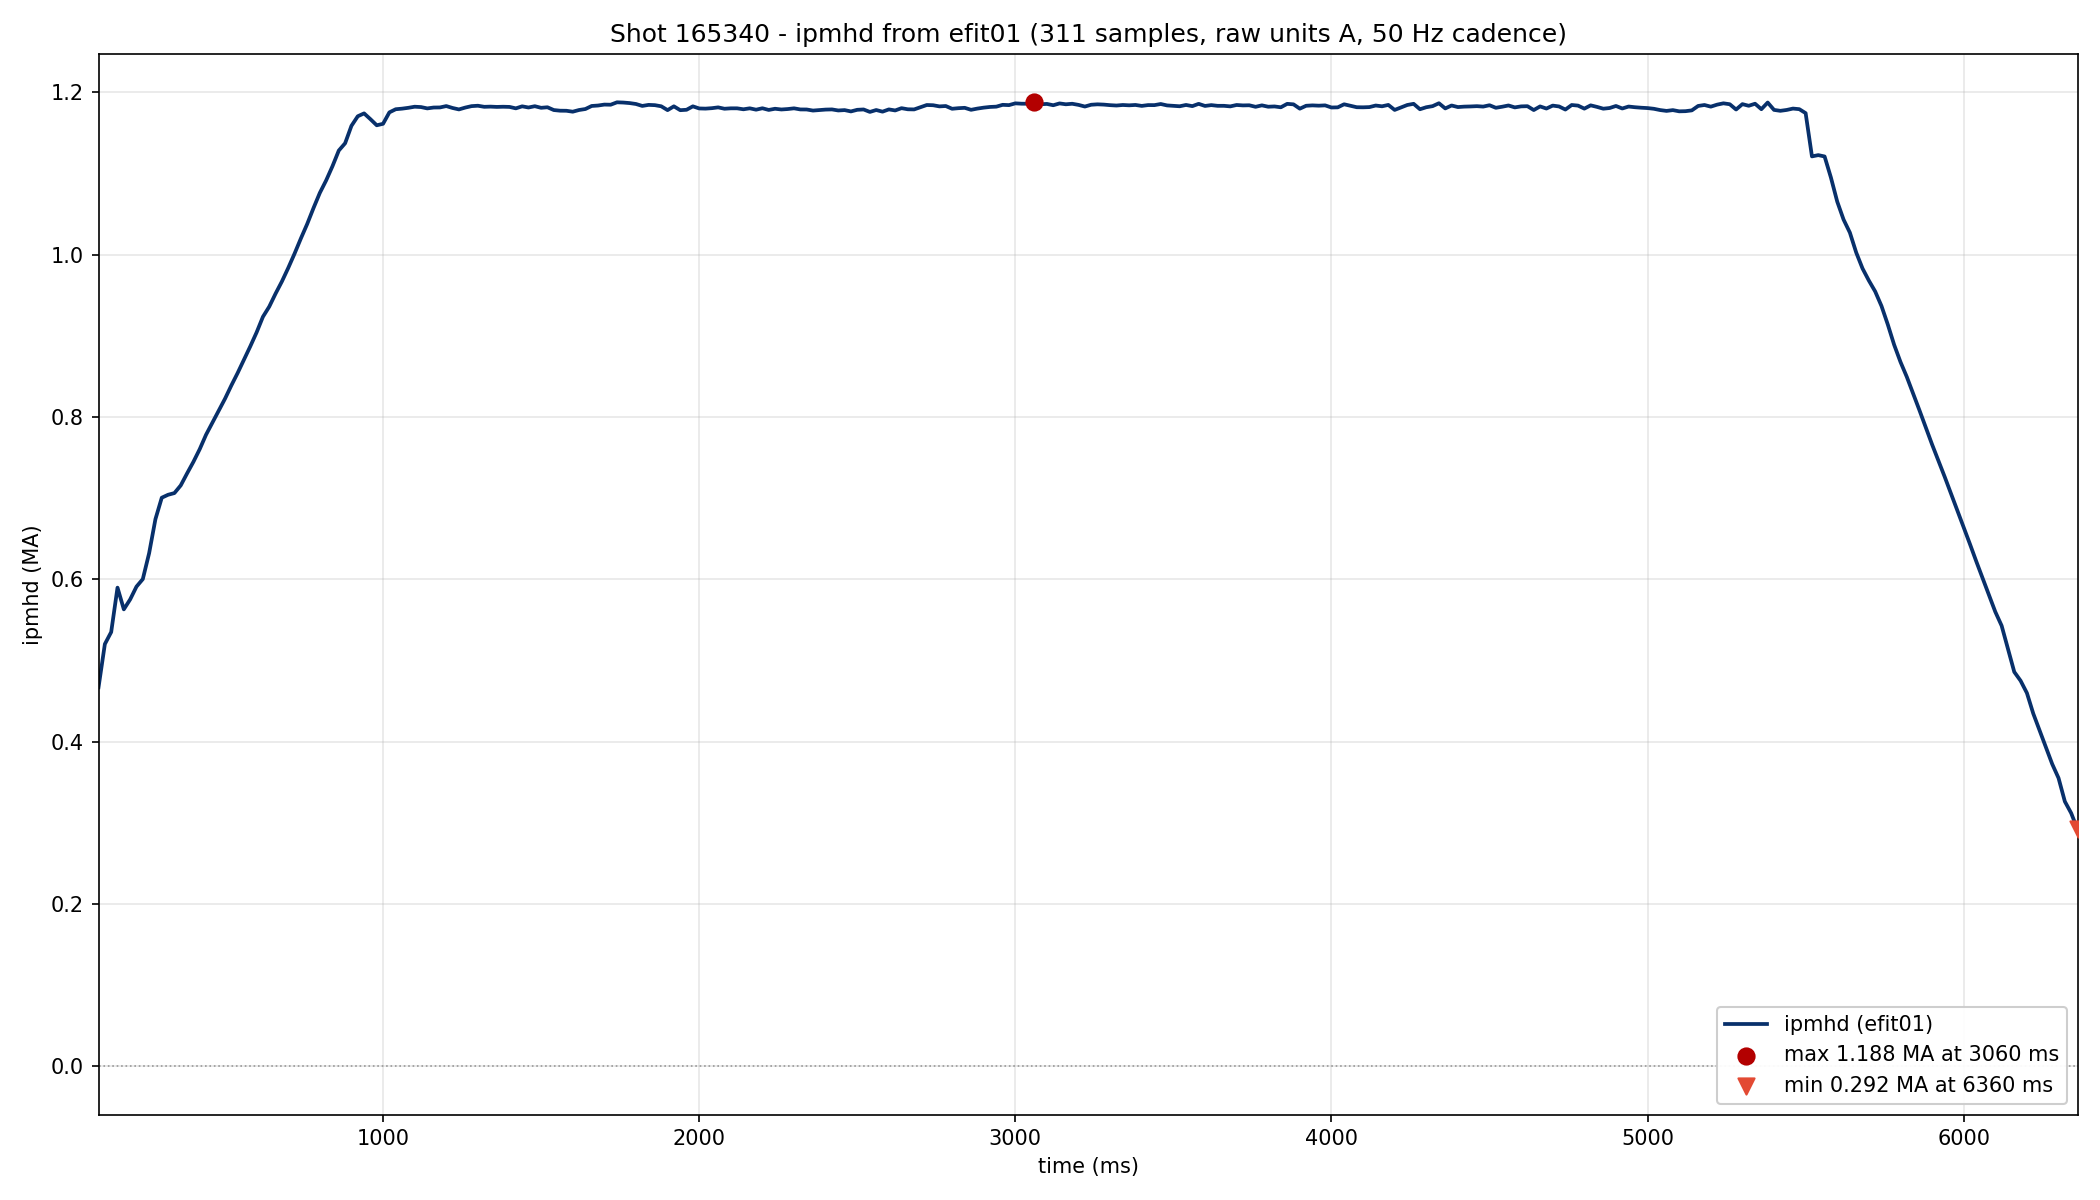

**Shape of the discharge.** The plateau is long and flat: 228 samples sit within 2% of the peak, from 1020 to 5500 ms (4.48 s), with a mean of 1,181,666 A and a standard deviation of only 3,031 A — about 0.26% ripple, so the flat-top is genuinely steady rather than a slow ramp. The current is above 1 MA from 720 to 5660 ms (4.94 s). Peak-to-flat-top ratio is 1.005, i.e. the maximum is essentially the plateau level and not a transient overshoot.

**Data files** (all in the working folder):

- `ipmhd_165340.csv` — the full trace, columns `time_ms,ipmhd_A`, 311 rows; every number above can be recomputed from it.
- `ipmhd_165340_summary.json` — sample count, min/max in A and MA, time base, cadence, plateau extent.
- `ipmhd_165340_extra.json` — flat-top statistics, first/last sample, time above 1 MA.
- `ipmhd_165340_stats.json` — sidecar written by the fetch script itself.
- `fetch_ipmhd_165340.py`, `plot_ipmhd_165340.py`, `summarize_ipmhd_165340.py`, `extra_ipmhd_165340.py`, `lookup_ipmhd_meaning.py` — the scripts that produced the above.

In [4]:
%%ask
Fetch \ipmhd from efit01 for shot 165340 and plot it versus time, and
report the number of samples and the min/max with units.

### Elongation
**Ask:** "plasma elongation" (no `\kappa` given) → should resolve to `efit01/\kappa`.

## Plasma elongation, DIII-D shot 165340

The elongation trace came back clean: **311 samples** on a uniform **20 ms** grid (50 Hz EFIT cadence), spanning **100 to 6360 ms** , all finite.

**The two requested numbers:**

| quantity | value | units |
|---|---|---|
| minimum | 1.436 | dimensionless |
| maximum | 1.945 | dimensionless |

The minimum is the **first** sample (100 ms, at the very start of the discharge) and the maximum is at **1840 ms** , early in the current flat-top. The trace is not monotonic — it rises from 1.436 to its peak, holds near 1.85–1.94 through the plateau, then falls back to 1.449 at the last sample (6360 ms), so both extremes are genuine features of the ramp-up and ramp-down rather than noise.


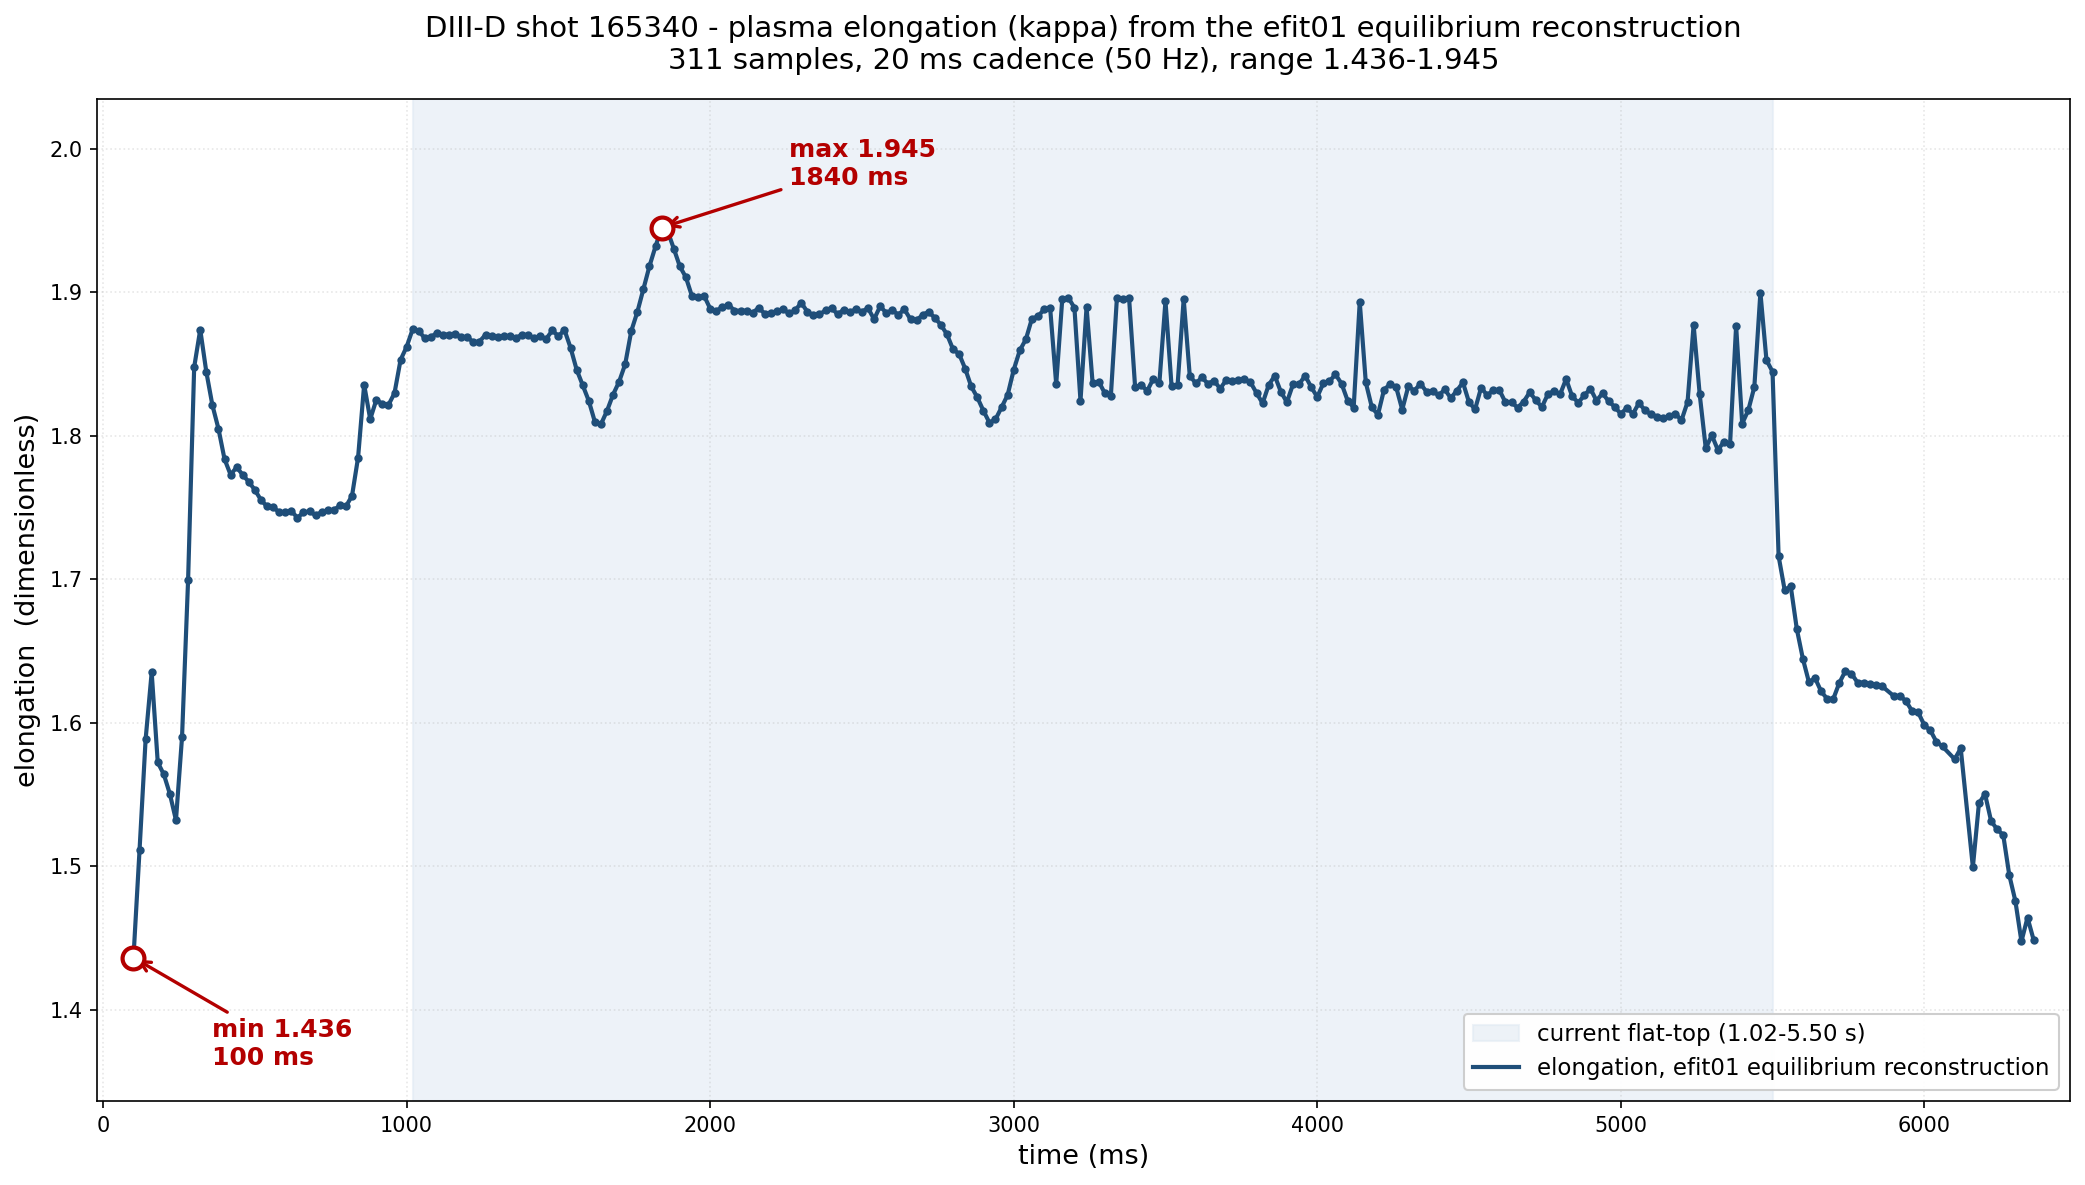

**What the signal is.** The elongation at the plasma boundary, from the EFIT equilibrium reconstruction — the node resolves to `\EFIT01::TOP.RESULTS.AEQDSK:KAPPA`, read from the node itself rather than from a catalog string. It is dimensionless. Worth noting: the node's own stored unit field is blank, so the "dimensionless" designation comes from the signal catalog's entry for this quantity, not from the data object.

**Shape of the discharge.** The elongation is high for most of the pulse: 250 of 311 samples sit at or above 90% of the peak (1.751), from 300 to 5500 ms. Over the current flat-top (1.02–5.50 s, taken from the `\ipmhd` trace measured earlier) the elongation averages **1.853** with a standard deviation of only **0.031** — a steady, well-controlled plateau. The longest run above 95% of peak (1.848) is 1720–2820 ms, 1.10 s, averaging 1.890 ± 0.017. Peak-to-peak across the whole shot is 0.509.

**Cross-check against the shot record.** The shot summary carries a single representative elongation of **1.83382** for this shot, which sits essentially at the trace's median of **1.833** — the two agree to three decimals. They are different kinds of number, though: the summary is one stored scalar per shot, while the 1.436–1.945 range above is the time-resolved trace's own extent. The summary also records the topology as lower-single-null (SNT), consistent with an elongated, diverted plasma.

**Data files** (all in the working folder):

- `kappa_165340.csv` — the full trace, columns `time_ms,kappa`, 311 rows; every number above can be recomputed from it.
- `kappa_165340_summary.json` — sample count, min/max with their times, time base, cadence, mean and median.
- `kappa_165340_extra.json` — plateau statistics, flat-top window statistics, first/last sample, and the resolved MDSplus node path.
- `fetch_kappa_165340.py`, `kappa_165340_meta.py`, `plot_kappa_165340.py` — the scripts that produced the above.

In [5]:
%%ask
For DIII-D shot 165340, fetch the plasma elongation from the MHD equilibrium
reconstruction, plot it versus time, and report its min and max.

### Safety factor at 95% flux surface
**Ask:** no "MHD equilibrium" qualifier this time — the harder disambiguation case.  
**Expected:** resolves to `efit01/\q95` anyway.

## Safety factor at the 95% flux surface, DIII-D shot 165340

The trace fetched cleanly: **311 samples** on a uniform **20 ms** grid (50 Hz EFIT cadence), spanning **100 to 6360 ms** , all finite.

**The requested range:**

| quantity | value | units |
|---|---|---|
| minimum | 4.558 | dimensionless |
| maximum | 9.438 | dimensionless |
| range (max − min) | 4.879 | dimensionless |

The minimum sits at **1820 ms** , inside the current flat-top. The maximum is the **last sample** (6360 ms) — the end of the ramp-down, where q95 climbs steeply as the plasma current collapses. So the two extremes are not symmetric features: the low end is a genuine flat-top value, the high end is a ramp-down endpoint.


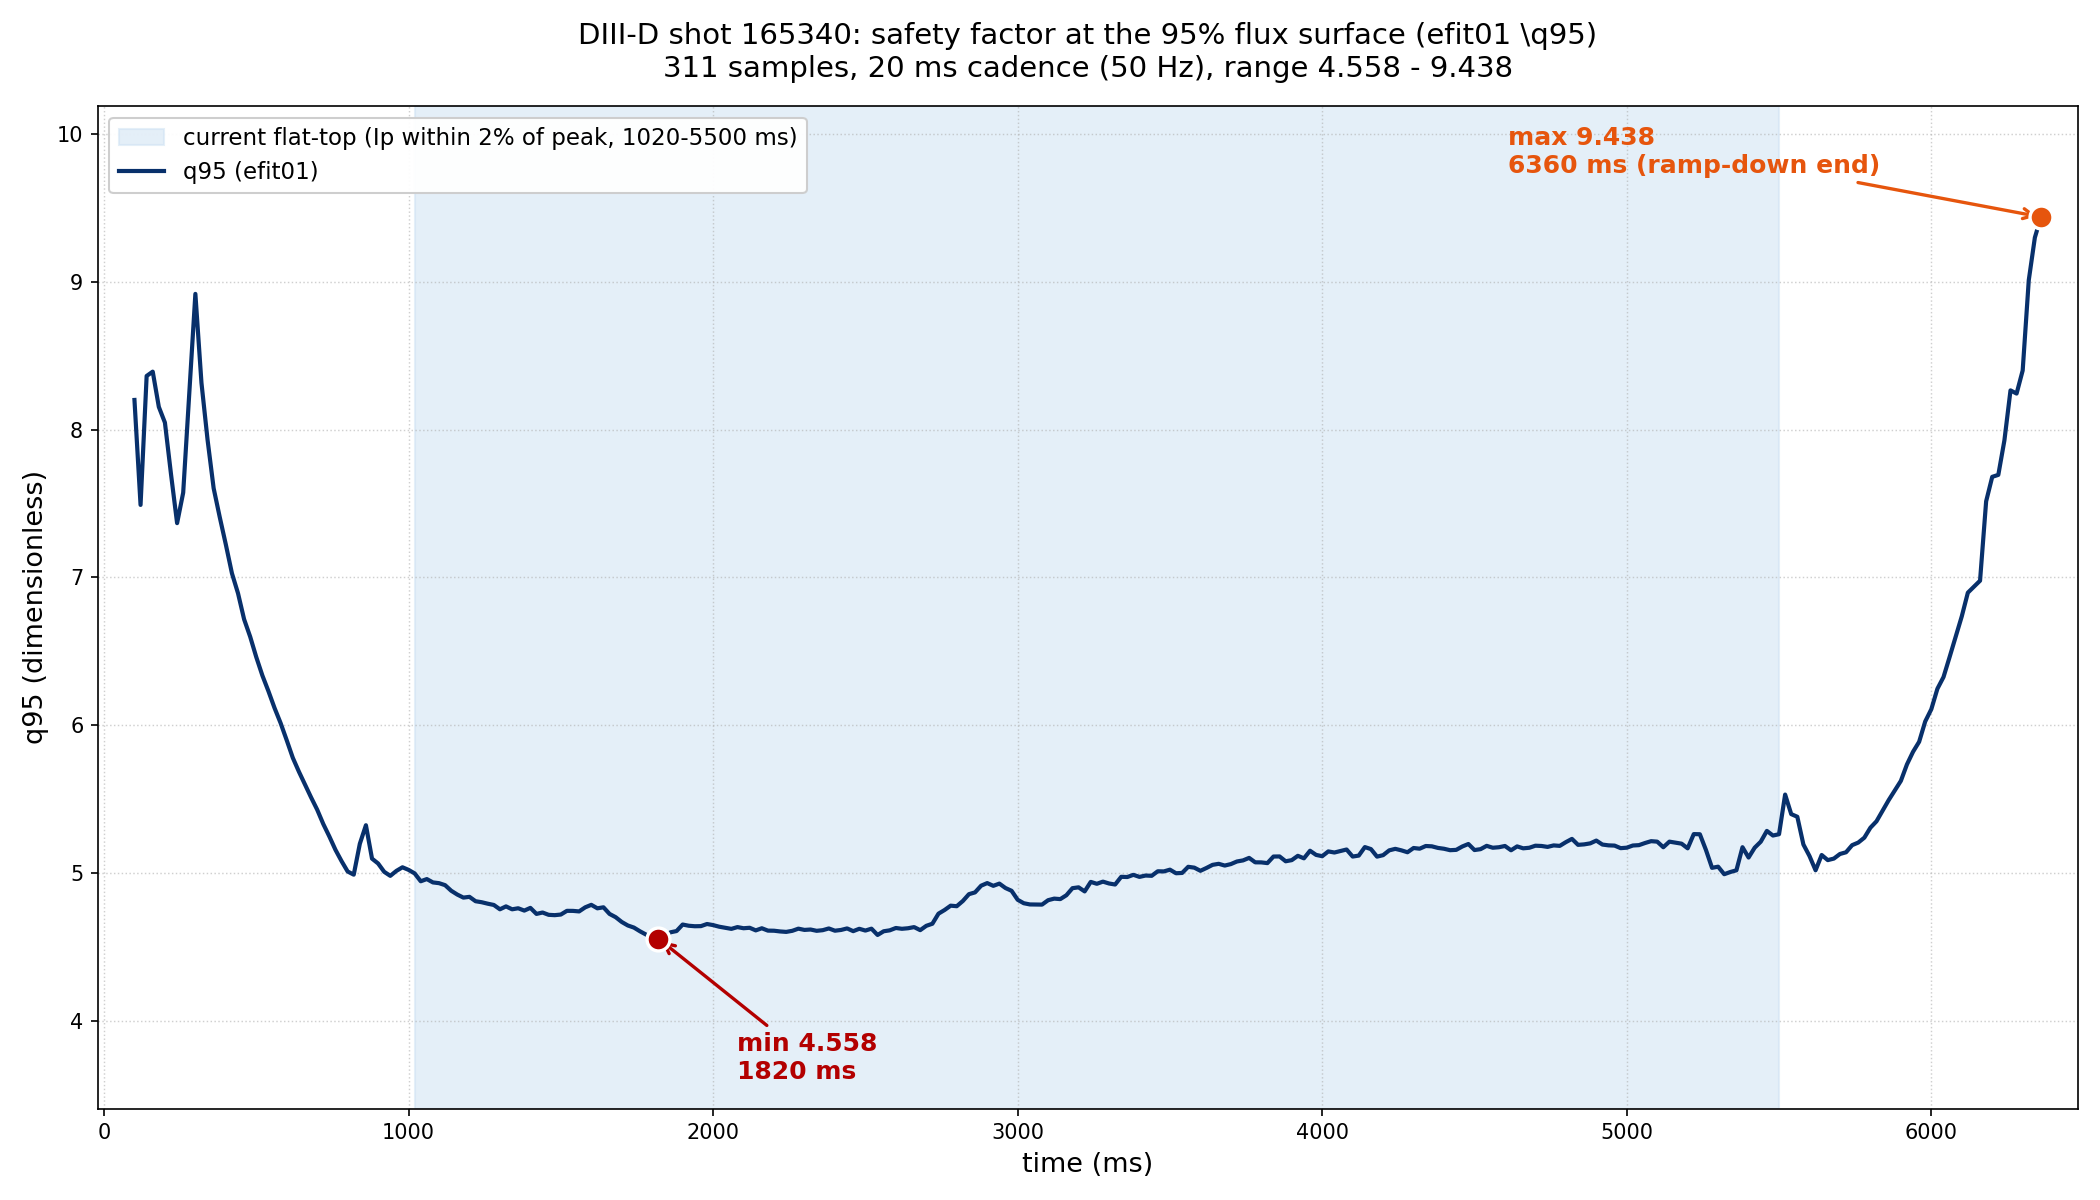

**What the signal is.** The catalog describes `\q95` as "q at 95% flux surface", dimensionless. The node resolves to `\EFIT01::TOP.RESULTS.AEQDSK:Q95` — read from the node itself via `getFullPath()`, not quoted from the catalog. One caveat worth stating: the EFIT01 catalog row for this name is marked "Unassigned Signal / unknown", and the node's own stored unit field is a single blank space. The description and the dimensionless designation therefore come from the catalog's **EFIT** -tree row for the same AEQDSK node, not from the EFIT01 entry.

**Shape of the discharge.** The flat-top is where q95 is low and steady: over the current plateau (1020–5500 ms, taken from the `\ipmhd` trace measured earlier) q95 averages **4.928 ± 0.223** , ranging 4.558 to 5.286 across 225 samples. The longest run within 5% of the minimum is **1280–2800 ms** (1.52 s), averaging 4.662. After the plateau the rise is steep and monotonic: 5.263 at 5500 ms, 5.088 at 5660 ms, 6.109 at 6000 ms, 7.680 at 6200 ms, reaching 9.438 at the final sample. The whole-shot mean of 5.329 sits well above the flat-top mean of 4.928 precisely because the ramp-down tail pulls it up.

**No shot-summary cross-check is available.** `q95` is not a column in the SUMMARIES table, so unlike the elongation there is no independent stored scalar to compare against — the range above is the trace's own extent and nothing else. For context, the same summary records `ip` 1.195 MA, `kappa` 1.834, pulse length 6.551 s, topology SNT.

**Data files** (all in the working folder):

- `q95_165340.csv` — the full trace, columns `time_ms,q95`, 311 rows; every number above can be recomputed from it.
- `q95_165340_summary.json` — sample count, min/max with their times, time base, cadence, mean and median.
- `q95_165340_extra.json` — flat-top statistics, longest low-q95 run, ramp-down spot values, and the resolved MDSplus node path.
- `fetch_q95_165340.py`, `q95_165340_meta.py`, `plot_q95_165340.py` — the scripts that produced the above.

In [6]:
%%ask
For shot 165340, fetch the safety factor at the 95% flux surface,
plot it versus time, and report its range.

### Multi-shot overlay
**Purpose:** test the fetch-many-shots-and-compare pattern, not just concept mapping.

## Plasma current from the equilibrium reconstruction, three shots overlaid

All three traces fetched cleanly from `efit01` — no errors, no non-finite samples, all on the same uniform **20 ms** grid (50 Hz EFIT cadence). The signal is `\ipmhd`, the fitted plasma current, in **amperes** .

**Peak current per shot:**

| shot | peak current | time of peak | samples | trace span |
|---|---|---|---|---|
| 165340 | **1.1878 MA** (1,187,813 A) | 3060 ms | 311 | 100–6360 ms |
| 188702 | **1.0066 MA** (1,006,573 A) | 1680 ms | 314 | 100–6960 ms |
| 194181 | **0.5993 MA** (599,271 A) | 1780 ms | 212 | 220–4560 ms |

All three carry positive current (no sign flip), so the peak is the trace maximum in each case.


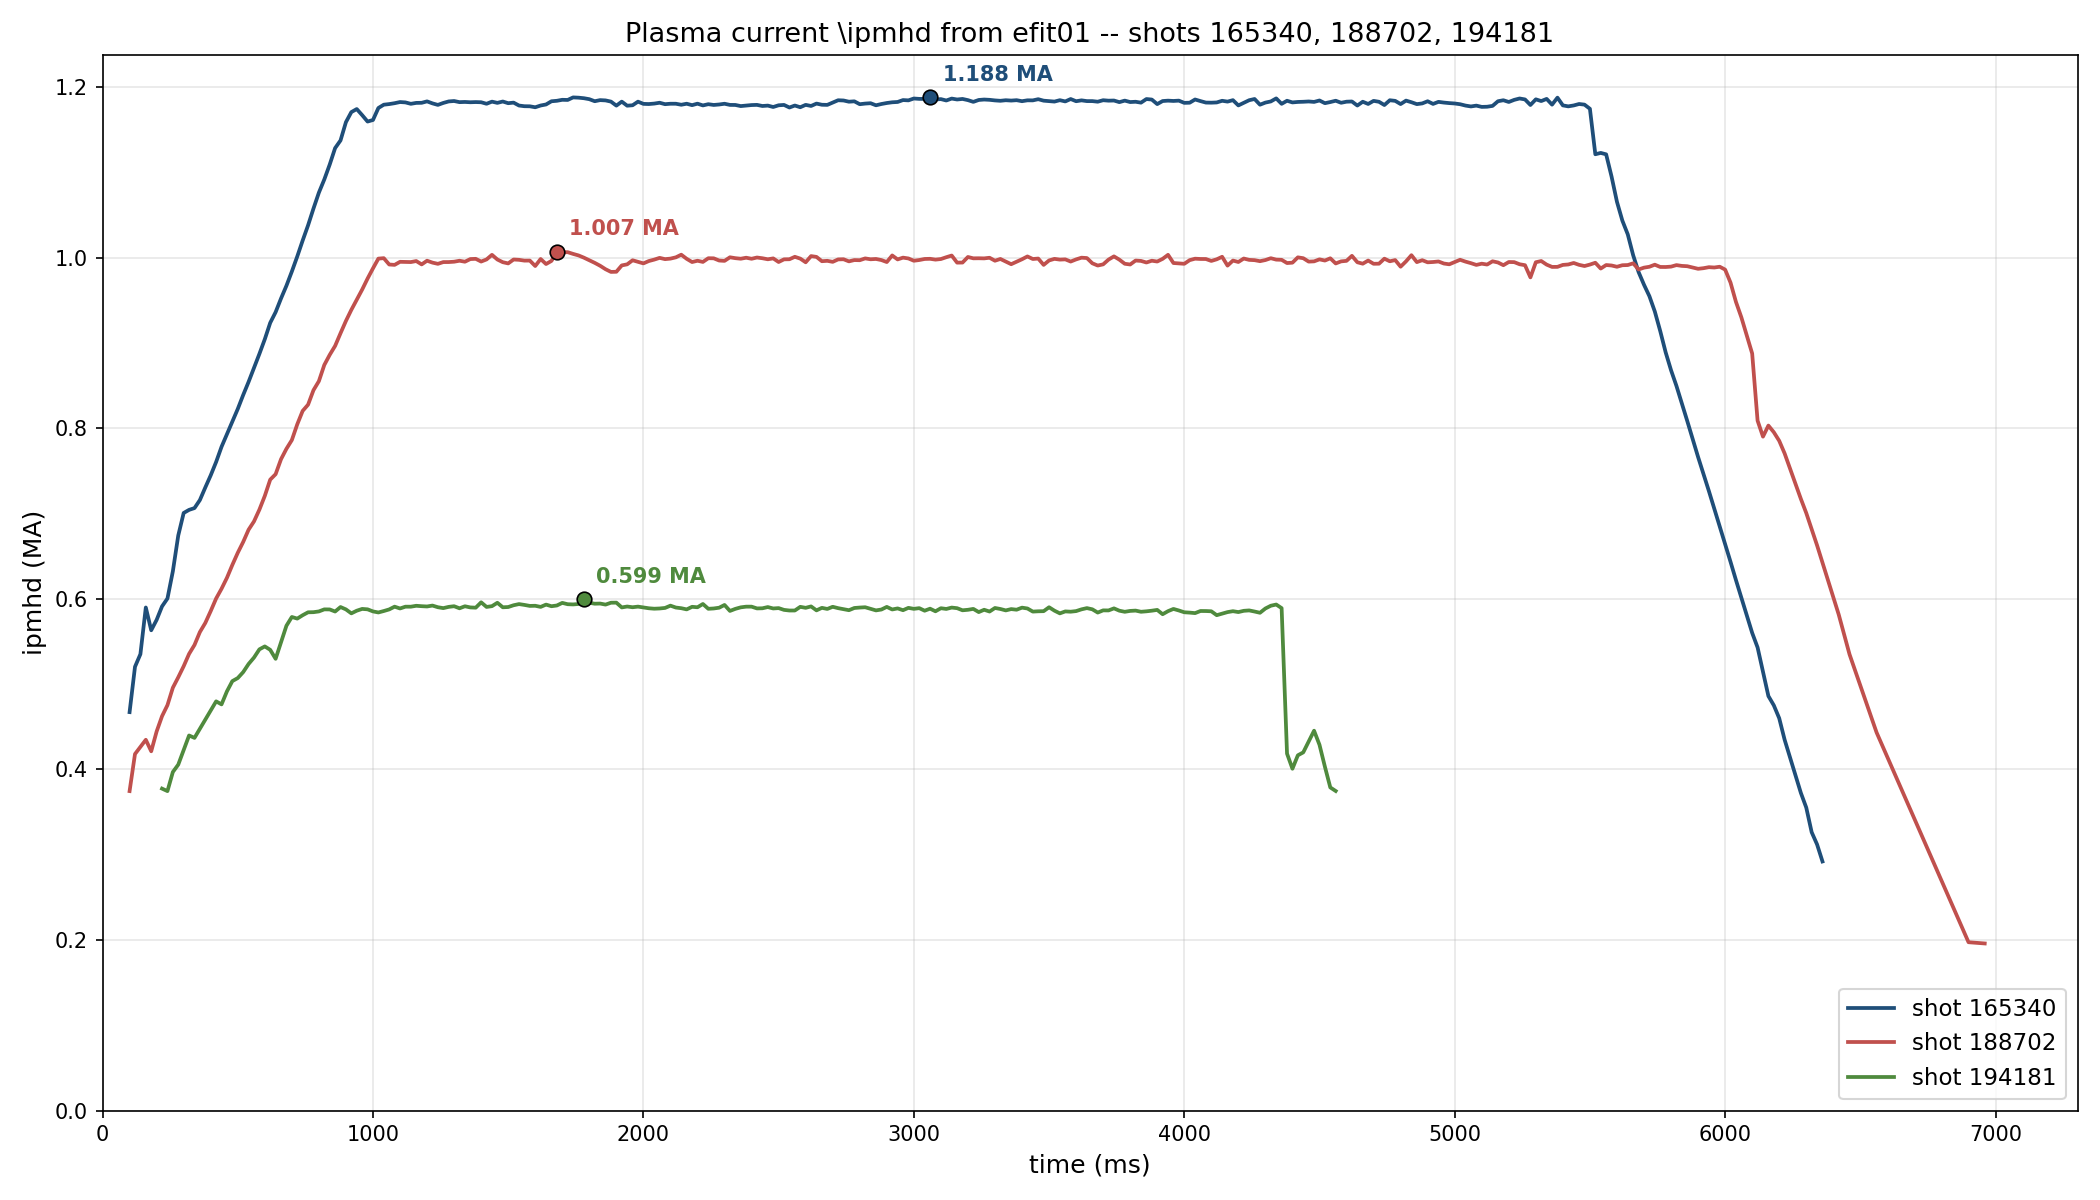

**The three discharges differ in more than level.** Shot 165340 is the strongest and longest-sustained: a 4.48 s plateau (1020–5500 ms) at 1.1818 MA with only 0.23% ripple. Shot 188702 reaches 1.0066 MA but holds a shorter 3.34 s plateau (1920–5260 ms) at 0.9966 MA, 0.29% ripple — and it is the longest pulse overall at 6.96 s of EFIT coverage, so its current is lower for longer. Shot 194181 is a genuinely different regime: 0.5993 MA peak, a 1.24 s plateau (1060–2300 ms) at 0.5914 MA, and the shortest trace at 4.34 s. Its 0.40% ripple is the largest of the three, though still under half a percent.

**Cross-check against the shot records.** The stored per-shot peak currents are 1.1946, 1.0161 and 0.6229 MA respectively — 0.57%, 0.95% and 3.94% above the trace maxima. These are two valid measurements of the same quantity through different pipelines, not a discrepancy to resolve: the stored value is a separately computed database scalar, the trace maximum is the empirical peak of the reconstruction itself. The gap is largest on 194181, and there the stored peak time (4363 ms) falls in the ramp-down where the trace reads 0.5662 MA — so the stored figure is not simply the trace's own maximum sampled at a different instant.

**Data files** (all in the working folder):

- `ipmhd_165340.csv`, `ipmhd_188702.csv`, `ipmhd_194181.csv` — the three traces, columns `time_ms,ipmhd_A`; every number above recomputes from these.
- `ipmhd_3shots_peaks.json` — per-shot sample count, peak with its time, min/max, cadence, sign.
- `ipmhd_3shots_plateaus.json` — plateau extent and duration, samples above 90% of peak.
- `ipmhd_3shots_verify.json` — flat-top mean/std/ripple, and the stored-versus-trace comparison.
- `ipmhd_3shots_summary_xcheck.json` — the shot-record values used in the cross-check.
- `fetch_ipmhd_3shots.py`, `plot_ipmhd_3shots.py`, `xcheck_ipmhd_3shots.py`, `verify_ipmhd_3shots.py` — the scripts that produced the above.

In [7]:
%%ask
For DIII-D shots 165340, 188702, and 194181, fetch the plasma current from the MHD
equilibrium reconstruction and overlay all three on a single chart. Report each
shot's peak current.

### Multi-shot shape comparison
**Purpose:** same multi-shot pattern, a dimensionless quantity (elongation) this time.

## Plasma elongation across shots 165340, 188702, 194181

All three traces fetched cleanly from `efit01` — no errors, no non-finite samples, all on the same **20 ms** grid (50 Hz EFIT cadence). The signal is `\kappa`, the elongation at the plasma boundary, dimensionless.

**Per-shot elongation:**

| shot | samples | span (ms) | min | max | median | peak-to-peak |
|---|---|---|---|---|---|---|
| 165340 | 311 | 100–6360 | 1.436 | **1.945** | 1.833 | 0.509 |
| 188702 | 314 | 100–6960 | 1.305 | **1.908** | 1.850 | 0.603 |
| 194181 | 212 | 220–4560 | 1.147 | **1.486** | 1.413 | 0.339 |


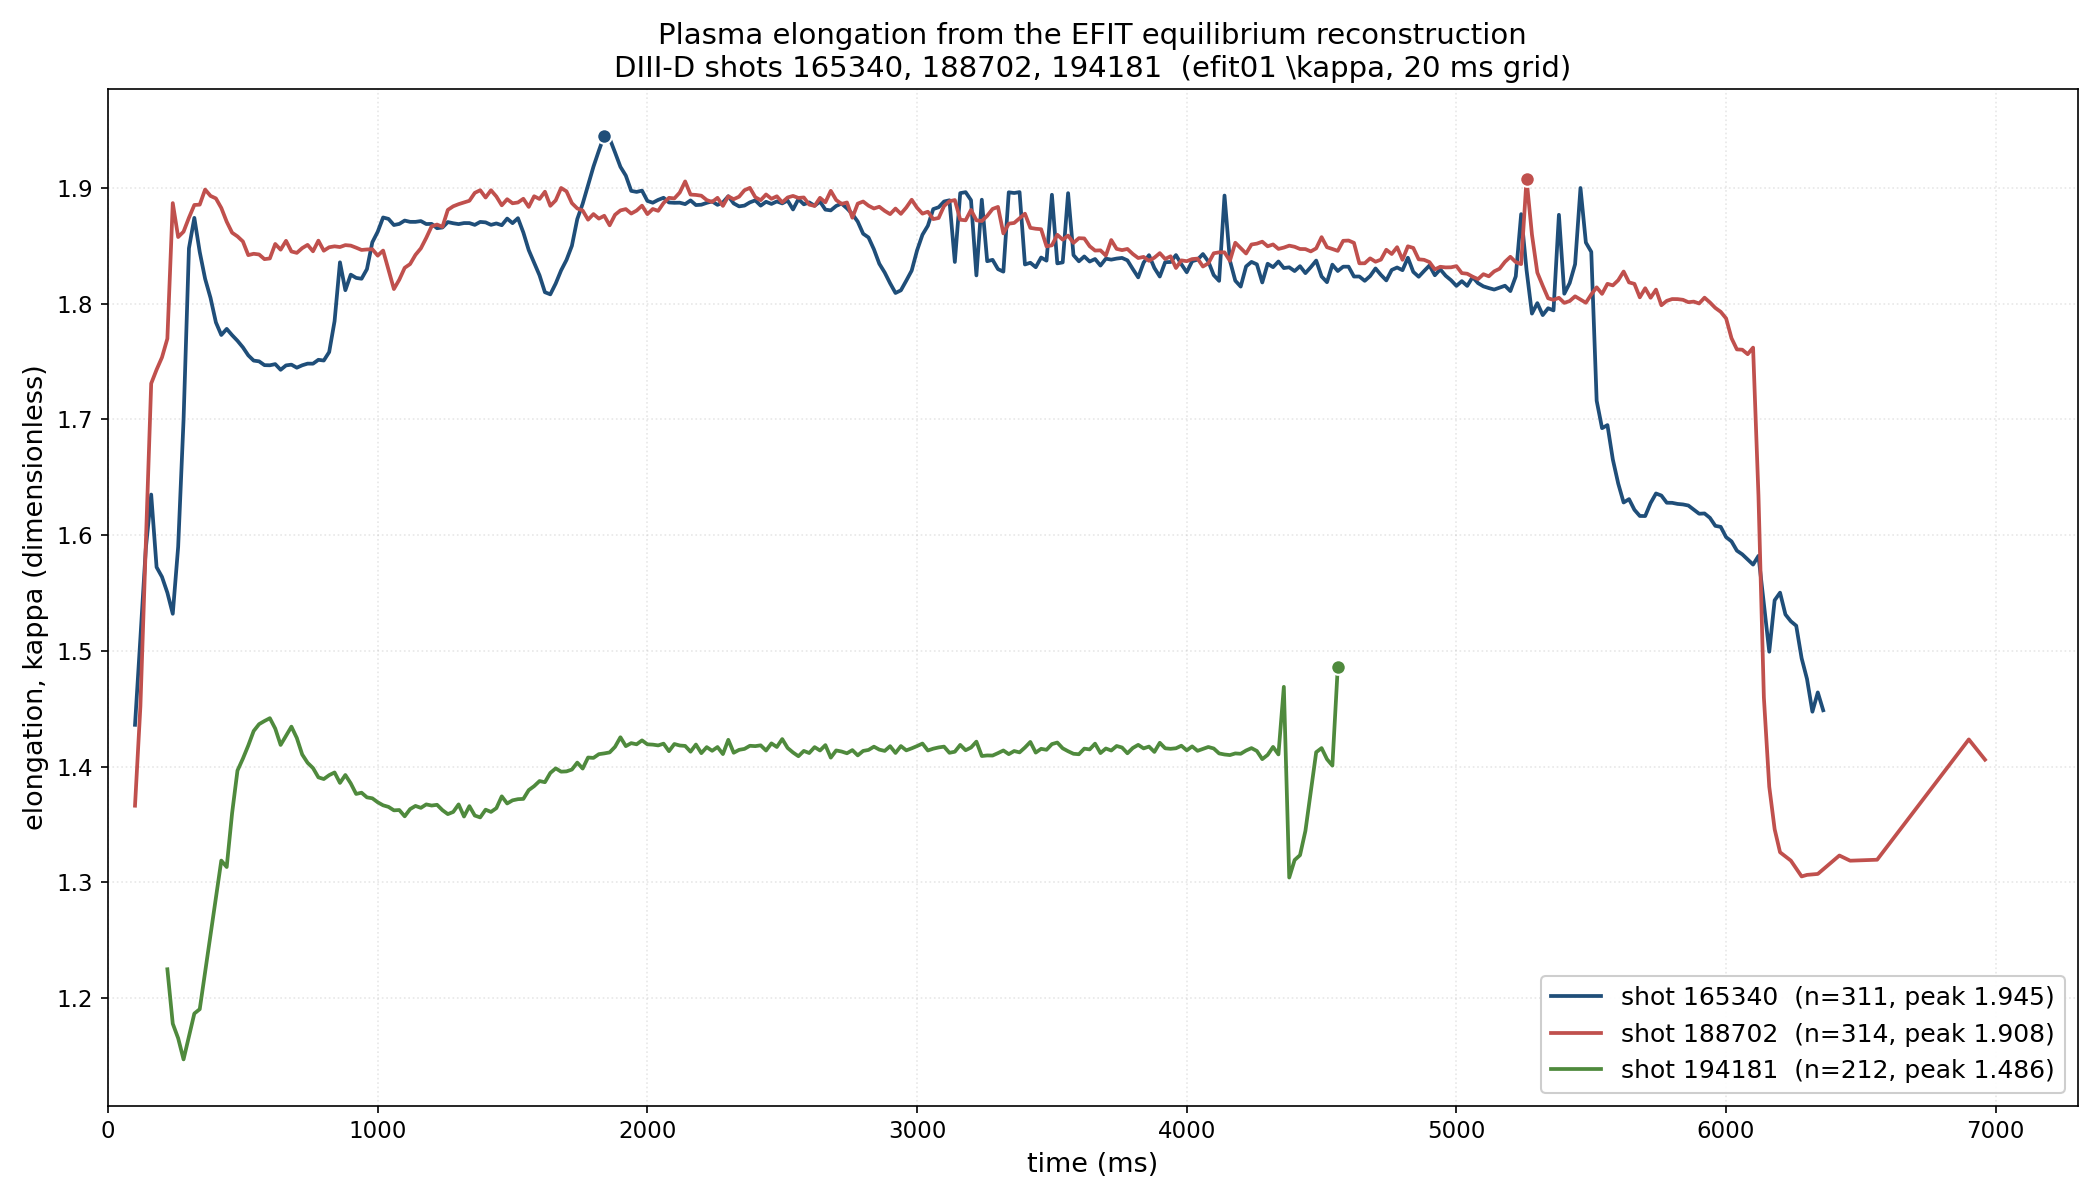

**The finding is that two shots are the same shape and the third is not.** 165340 and 188702 are near-twins: peaks 1.945 and 1.908, medians 1.833 and 1.850, and both hold a high, flat elongation for most of the pulse. 194181 is a distinctly lower-elongation discharge — its peak of 1.486 sits *below* the other two shots' medians, and its whole trace spans only 0.339, so it is not merely a scaled-down copy but a different operating shape. Its stored current is also the lowest of the three (0.623 MA against 1.195 and 1.016 MA), so the lower elongation tracks the lower-current regime.

**Comparing at matched conditions.** Whole-shot statistics mix ramp-up and ramp-down, so I also measured each trace over its own current flat-top (windows derived from the `\ipmhd` traces measured earlier):

| shot | flat-top window (ms) | elongation mean ± std | flat-top min–max |
|---|---|---|---|
| 165340 | 1020–5500 | 1.853 ± 0.031 | 1.790–1.945 |
| 188702 | 1920–5260 | 1.862 ± 0.023 | 1.821–1.908 |
| 194181 | 1060–2300 | 1.392 ± 0.024 | 1.356–1.425 |

On the plateau the two high shots agree to **0.009** in the mean — 0.5% apart — while 194181 sits 0.47 below them. All three are steady in flat-top (std 0.02–0.03), so the separation is a real difference in plasma shape, not scatter.

**Where the extremes come from.** For 165340 the minimum is the first sample (100 ms, ramp-up) and the maximum is at 1840 ms, early in the flat-top. For 188702 the maximum is at 5260 ms, the last flat-top sample, and the minimum at 6280 ms in the ramp-down. For 194181 the minimum is at 280 ms (ramp-up) and the maximum is the **final sample** (4560 ms) — a single-sample jump of +0.085 off a 1.401 neighbour, so that peak is an edge artifact of the reconstruction's last frame rather than a sustained shape. Excluding the first and last samples, 194181's interior maximum is **1.469** at 4360 ms. I report 1.486 as the trace maximum because that is what the data contains, but 1.469 is the defensible physical peak.

**Cross-check against the shot records.** The stored per-shot elongations are 1.83382, 1.87399 and 1.41828. Each sits within 0.025 of its trace's **median** (differences +0.0009, +0.0245, +0.0057) — the stored scalar is a representative mid-discharge value, not the trace maximum, which is why it falls 0.03–0.11 below the peaks. These are two valid measurements of the same quantity through different pipelines, not a discrepancy.

**What the signal is.** The catalog describes `\kappa` as "elongation at plasma boundary", units "(dimensionless)". The node resolves to `\EFIT01::TOP.RESULTS.AEQDSK:KAPPA`. One caveat: the EFIT01 catalog row for this name is marked "Unassigned Signal / unknown" and the node's own unit field is a single blank space, so the description and dimensionless designation come from the catalog's **EFIT** -tree row for the same AEQDSK node.

**Data files** (all in the working folder):

- `kappa_165340.csv`, `kappa_188702.csv`, `kappa_194181.csv` — the three traces, columns `time_ms,kappa`; every number above recomputes from these.
- `kappa_3shots_summary.json` — per-shot sample count, min/max with times, cadence, units.
- `kappa_3shots_stats.json` — mean, median, std, peak-to-peak, and the 90%-of-peak run statistics.
- `kappa_3shots_flattop.json` — flat-top windows and elongation statistics within them.
- `kappa_3shots_edges.json` — time-base gap check and whether each extreme is an edge sample.
- `kappa_3shots_spot.json` — spot values along each trace.
- `kappa_3shots_xcheck.json` — stored per-shot elongation and current from the shot catalog, with the differences.
- `kappa_3shots_meaning.json` — the catalog's description and units for `\kappa`.
- `fetch_kappa_3shots.py`, `plot_kappa_3shots.py`, `kappa_3shots_stats.py`, `kappa_3shots_flattop.py`, `kappa_3shots_edges.py`, `kappa_3shots_spot.py`, `kappa_3shots_xcheck.py`, `kappa_3shots_meaning.py` — the scripts that produced the above.

In [8]:
%%ask
Compare the plasma shape across DIII-D shots 165340, 188702, and 194181 by fetching
the elongation from the MHD equilibrium reconstruction and overlaying it versus time
on one chart with a legend.

## 2. Metadata from Database

The shot metadata is served by the FEDER lakehouse over HTTP -- there is nothing to download and nothing to place in a folder. It needs outbound network and a valid FDP token (`~/.fdp/token`, or the copy under `~/work/_User-Persistent-Storage_CephBlock_/.fdp/token`) -- the same token DIII-D data access already uses.

## DIII-D plasma shots between 190000 and 195000

**There were 3,507 plasma shots** in that range, inclusive of both endpoints.

Four independent queries agree on that number: the documented range helper, a plain `COUNT(*)` with `BETWEEN`, a `COUNT(*)` with explicit `>=`/`<=`, and a join against the shot-type table filtered to `plasma`. The endpoints themselves are both present (190000 and 195000 are real shots), so the inclusive count is the right one — an exclusive count would give 3,505.

**The range is not fully populated.** The span 190000–195000 covers 5,001 possible shot numbers, so **1,494 numbers in it are not plasma shots** — they were either never fired, or were non-plasma test/calibration shots that this archive excludes by design. The 3,507 present shots form **313 separate contiguous runs** , and those runs decode back to exactly 3,507, so no gaps are being hidden by compression.

**Every row in this archive is a plasma shot.** The shot-type table contains only `plasma` — 90,644 rows, all of them — so the 3,507 figure is the plasma count and the total count at once. There is no separate non-plasma population to subtract here. Worth flagging: the shot records carry a field that looks like a plasma flag, but it is unpopulated and stored as text, so filtering on it errors out rather than returning a wrong number. I did not use it; the count comes from the shot list itself.

**Campaign structure.** The 3,507 shots span **2022-06-20 to 2023-04-04** — about 9.5 months — across **227 run sessions** , averaging **15.5 shots per session** . The busiest single session was **20220812 with 47 shots** ; the quietest were single-shot sessions (192822 on 20221114, 193337 on 20221206). The longest break between sessions was **31 days** , from 2022-09-30 to 2022-10-31 — the autumn shutdown. A second long break of 22 days separates 193373 (2022-12-07) from 193484 (2022-12-22), and 88 shot numbers are skipped between 191067 and 191155 across the August gap.


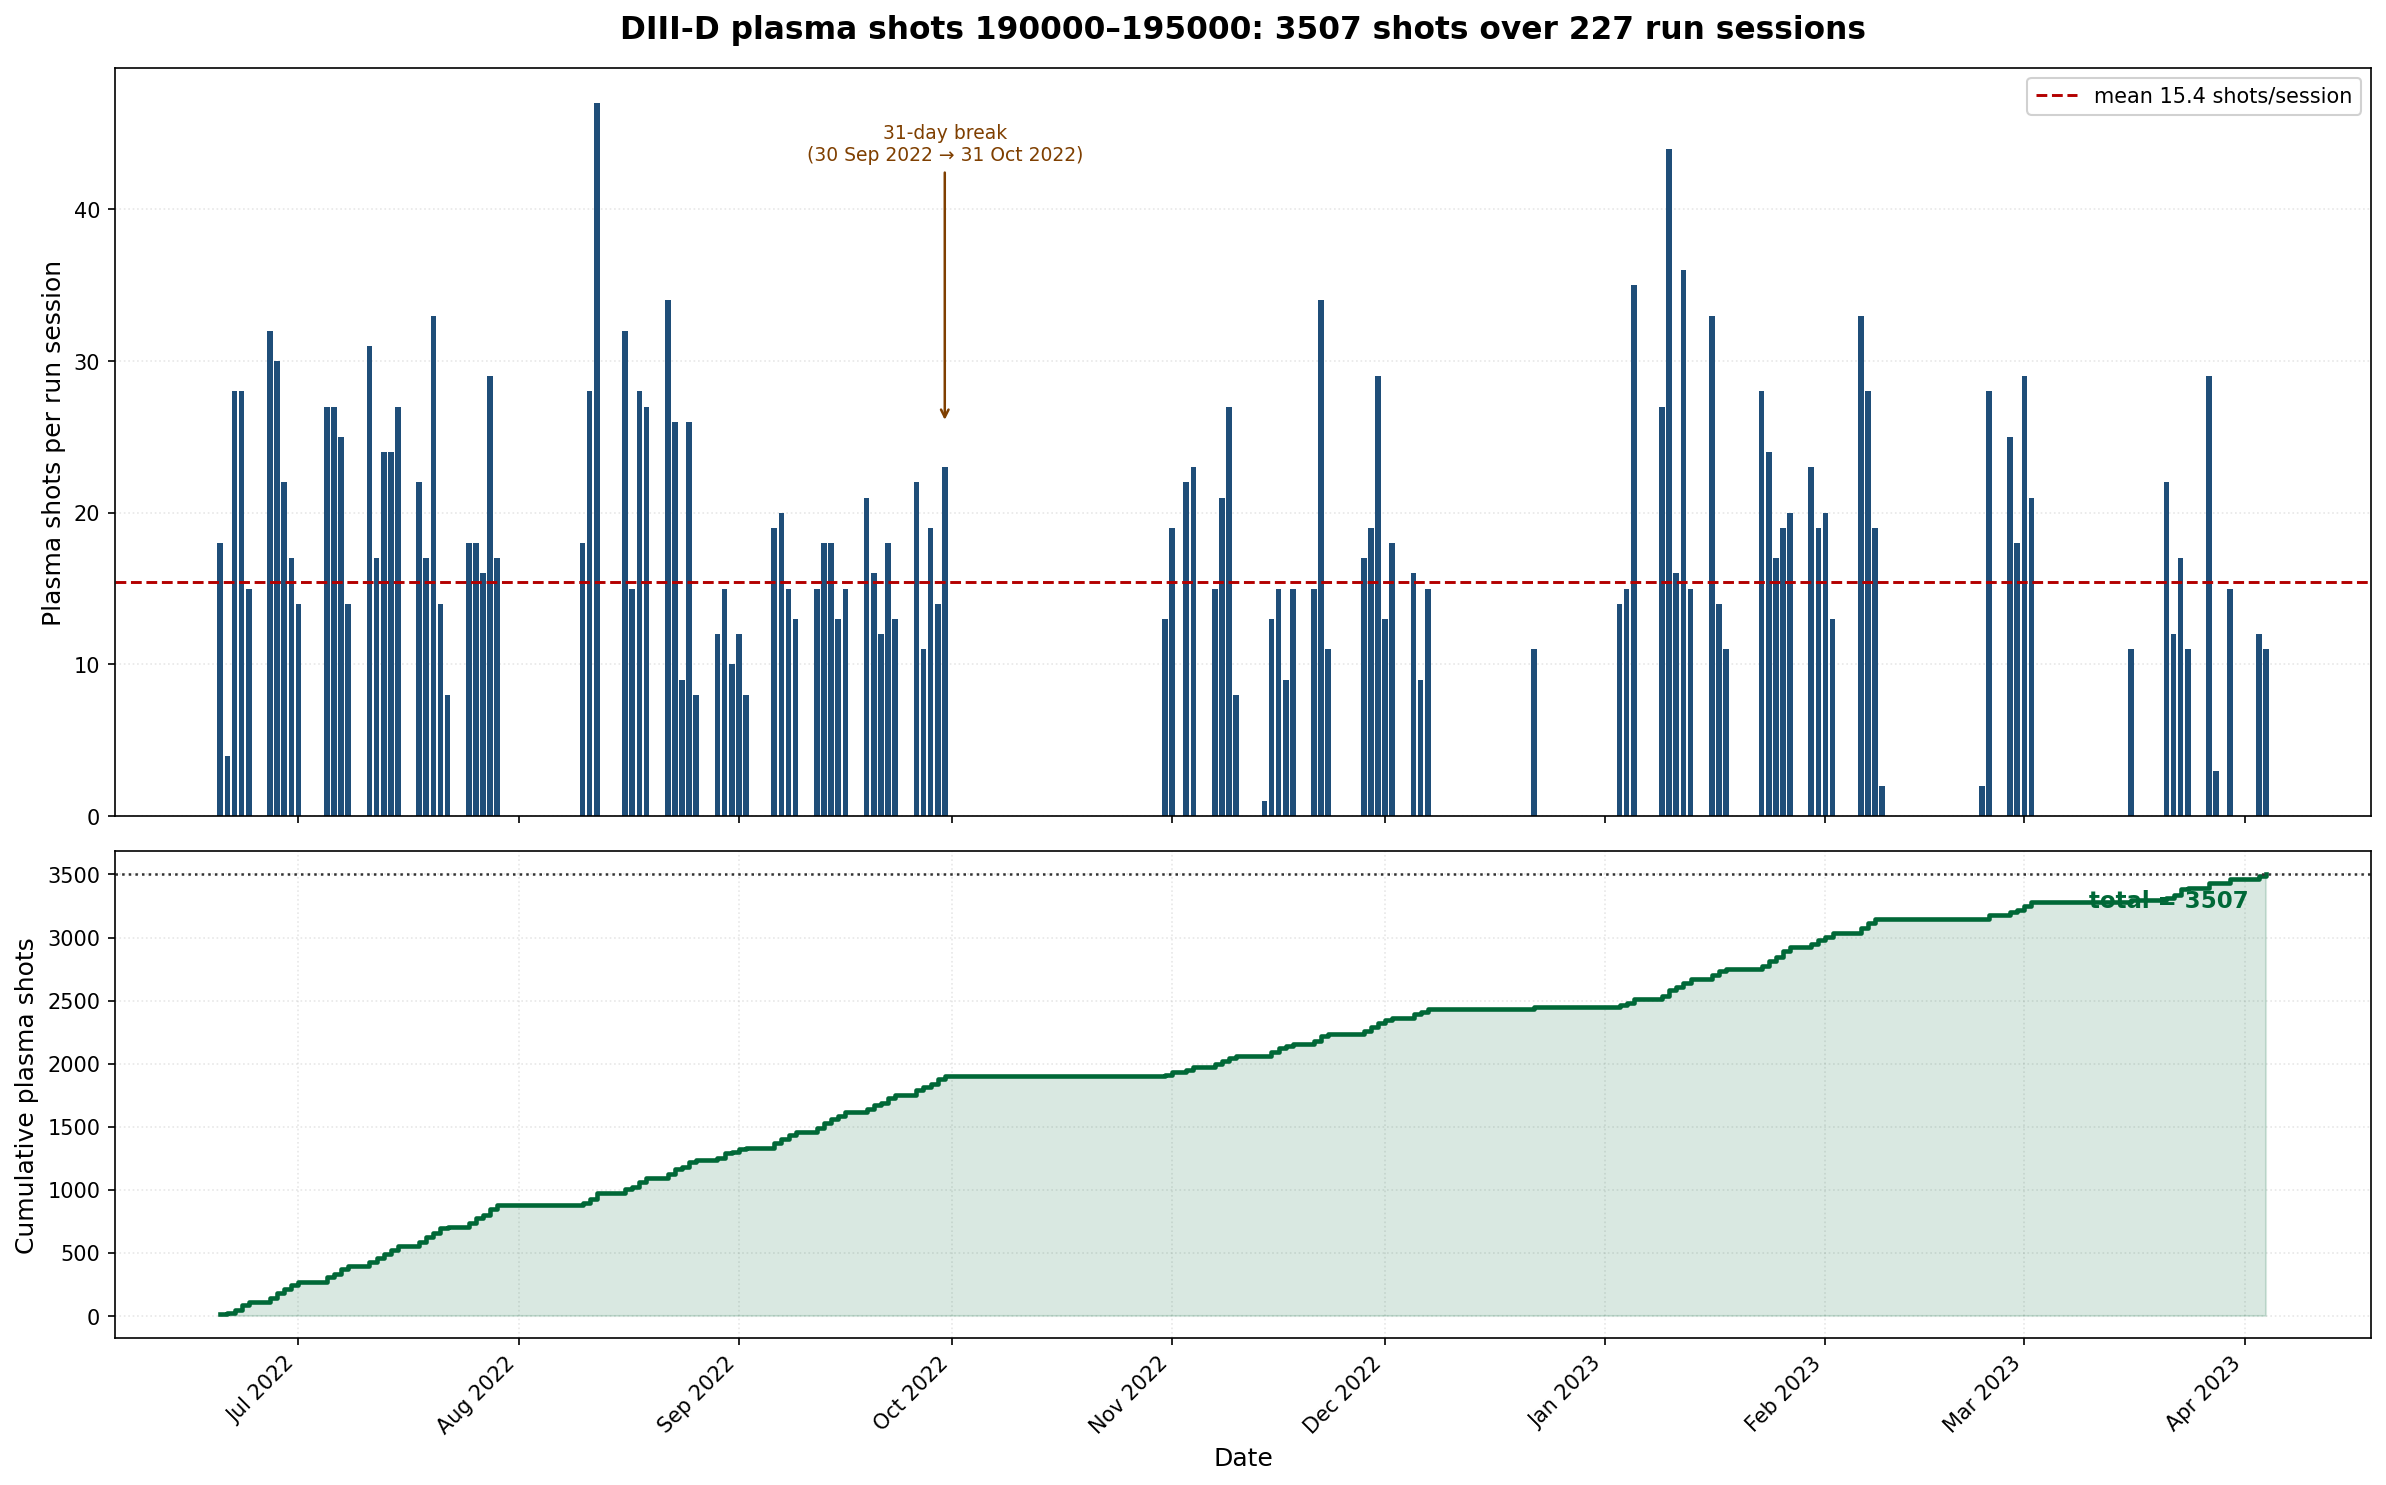

The upper panel shows the per-session cadence — a dense, fairly regular experimental campaign with the two shutdown gaps visible as blank stretches. The lower panel shows the cumulative total climbing steadily to 3,507, with no long flat plateau, meaning shots accumulated at a roughly constant rate through the campaign rather than in a few bursts.

**One caveat on scope.** This is a snapshot of the shot archive, filtered to plasma-type shots, and it may lag the live DIII-D database. The count is exact for this snapshot; a live query could differ if shots have been added or reclassified since.

**Data files** (all in the working folder):

- `shots_190000_195000_count.json` — the count from all four methods, boundary probes, the 313 contiguous runs with their decode check, and the gap arithmetic.
- `shots_190000_195000_context.json` — the join cross-check, all 227 run sessions with shot ranges, the date span, and the largest inter-shot gaps.
- `shots_190000_195000_by_run.csv` — one row per run session: `run,date,n_shots,shot_lo,shot_hi`; the 3,507 total is the sum of the `n_shots` column.
- `shots_190000_195000_timeline.json` — the campaign summary statistics behind the chart.
- `count_shots_190000_195000.py`, `context_shots_190000_195000.py`, `plot_shots_190000_195000.py` — the scripts that produced the above.

In [9]:
%%ask
How many DIII-D plasma shots were there between 190000 and 195000?

In [1]:
%%ask
Look up shot 190000's elongation and peak plasma current from the DIII-D 
shot records.

## Shot 190000 — elongation and peak plasma current from the shot records

Both values read directly from the DIII-D shot records:

| quantity | value | units |
|---|---|---|
| elongation | **1.71117** | dimensionless |
| peak plasma current | **911,396 A** (0.9114 MA) | amperes |

The peak current is recorded at **2.23262 s** into the discharge. The record also gives the flat-top current as 889,010 A (0.889 MA), so the peak sits about 2.5% above the plateau — a normal overshoot at the start of flat-top rather than a separate event.

**Supporting shot context** (same record): pulse length 5.504 s, toroidal field −1.875 T, minor radius 0.610 m, major radius 1.739 m, upper/lower triangularity 0.424 / 0.723, magnetic axis at Z = −0.050 m, topology SNB (single-null, bottom). The shot was fired **2022-06-20 13:12:51** in run session 20220620.

**Cross-check against the equilibrium reconstruction.** I also fetched the time-resolved traces for this shot, and the stored scalars behave as expected — they are representative single values, not trace extremes:

- **Elongation** : the trace runs 1.082 to 1.833 over 256 samples (100–5320 ms, 20 ms cadence). The stored 1.71117 sits **0.0043 above the trace median** of 1.7069 — essentially the mid-discharge value. It is 0.122 below the trace maximum, which is the expected relationship, not a discrepancy.
- **Peak current** : the trace's own maximum is **896,383 A at 2100 ms** , so the stored 911,396 A is **1.67% higher** . These are two valid measurements of the same quantity through different pipelines — the stored figure is a separately computed database value, the trace maximum is the empirical peak of the reconstruction. The stored peak time (2.233 s) and the trace peak time (2.100 s) differ by 133 ms, about 6.6 EFIT sample intervals.

**Provenance note on units.** The current node resolves to `\EFIT01::TOP.RESULTS.AEQDSK:IPMHD` and carries the unit string `A` on the node itself, so the ampere figure is confirmed at the source. The elongation node resolves to `\EFIT01::TOP.RESULTS.AEQDSK:KAPPA`, but its stored unit field is a single blank space — the dimensionless designation comes from the catalog's **EFIT** -tree entry for the same AEQDSK node ("elongation at plasma boundary", "(dimensionless)"), not from the EFIT01 entry, which is undocumented. Both paths were read from the fetched node's own `getFullPath()`, not quoted from the catalog.

**Data files** (all in the working folder):

- `shot_190000_lookup.json` — the full shot-record row: elongation, peak and flat-top current with their times, plus shape, field, timing and topology fields, and the catalog descriptions for both signals.
- `shot_190000_trace_xcheck.json` — the equilibrium traces' statistics and the stored-versus-trace comparison for both quantities.
- `shot_190000_nodes.json` — the resolved MDSplus node paths, node unit strings, and trace time bases.
- `lookup_190000.py`, `xcheck_190000_traces.py`, `nodes_190000.py` — the scripts that produced the above.

## Shot 165340 fired on Thursday, 28 January 2016 at 10:46:13

**Shot 165340 occurred on 2016-01-28 at 10:46:13** — a Thursday morning, mid-way through the day's experimental session.

**Two independent timestamps agree.** The shot record carries the firing time as `2016-01-28 10:46:13`, and the record-entry timestamp is `2016-01-28 10:46:06.890` — 6.1 seconds earlier. Across the ten shots of that session the entry timestamp consistently precedes the firing time by **+3.8 to +6.8 s** (mean +5.3 s), which is the expected bookkeeping lag: the record is written as the shot is set up, and the firing time is stamped at discharge. The two fields are not copies of each other, and their agreement to within a few seconds is a real consistency check rather than a tautology.

**No timezone is recorded.** Both fields are stored as plain text with no offset suffix, so the times are as the archive holds them — DIII-D local time (Pacific). I have not converted them, and a reader comparing against UTC should apply the offset themselves.

**Where it sits in the day.** Shot 165340 was the **5th of 10 plasma shots** in run session `20160128`, which ran from 08:44:49 to 12:30:15. It came **1393 s (23.2 min) after shot 165339** and **677 s (11.3 min) before shot 165341** — a slightly longer pause before it than after, consistent with an intervening setup or diagnostic change.

**A second session followed on the same date.** Eight further shots (165348–165355) ran from 13:14 to 16:14 under the separate run label `20160128A`, bringing the day's total to **18 plasma shots** . This is why a naive count of shots sharing that date returns 18 while the session containing 165340 holds 10 — the two figures measure different things, and both are correct.

**The discharge itself** , for anchoring: pulse length 6.55 s, peak plasma current 1.1946 MA at 1.764 s, elongation 1.834, toroidal field 1.857 T, upper single-null topology. This is the same shot whose current and elongation traces were measured in the earlier comparisons, so the timestamp attaches to a discharge already characterised in this session.


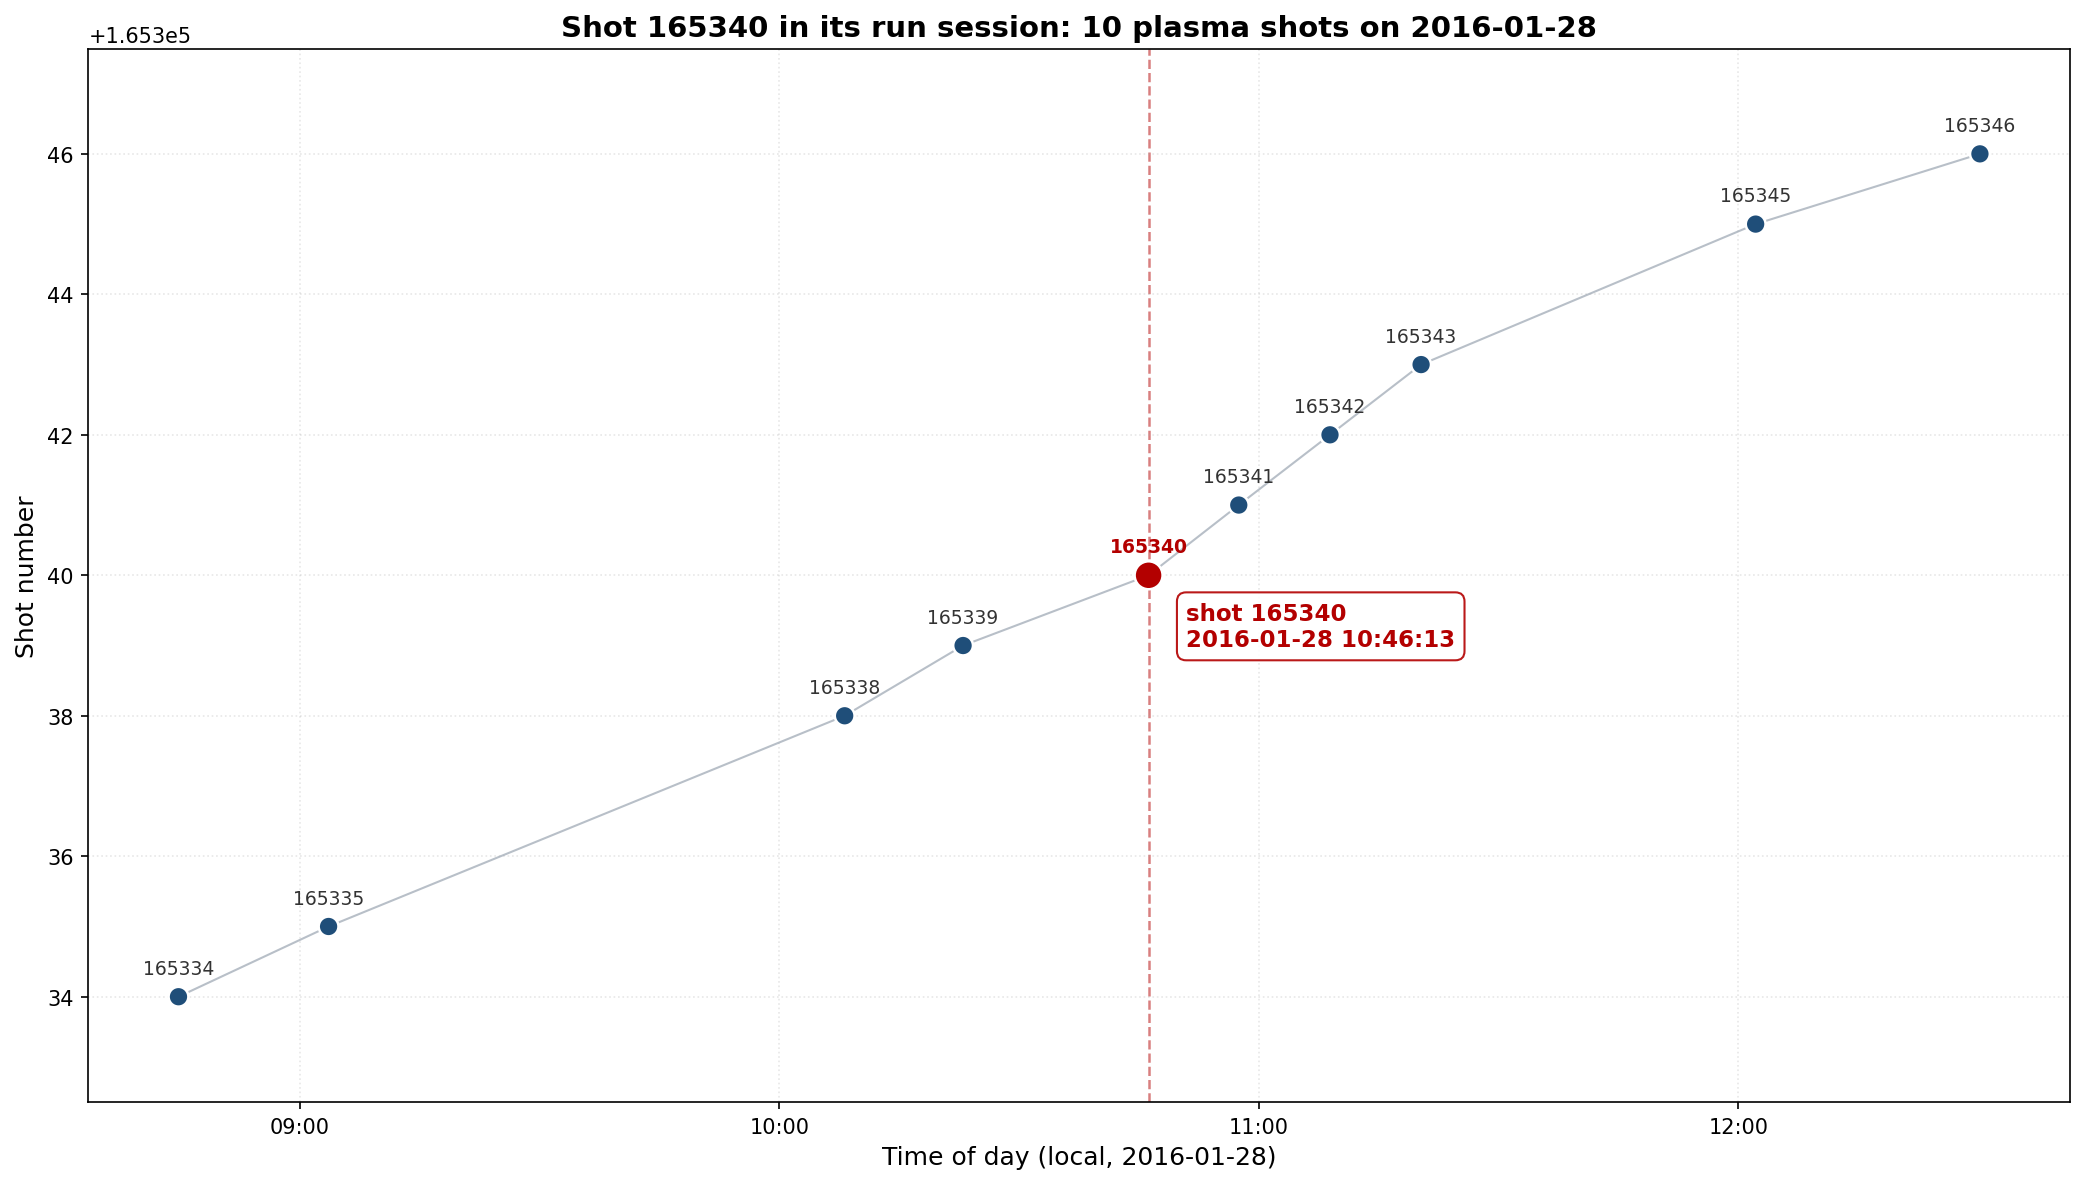

**Data files** (all in the working folder):

- `shot_165340_when.json` — the shot's timing fields, run label, and the ten shots of session `20160128` with both timestamps.
- `shot_165340_when_verify.json` — column storage types, the per-shot entry-to-firing offsets, weekday, timezone check, and physics context.
- `shot_165340_timeline.json` — all 18 same-day shots grouped by run label, the session sequence, and the gaps around the focal shot.
- `when_165340.py`, `when_165340_verify.py`, `when_165340_timeline.py` — the scripts that produced the above.

In [2]:
%%ask
When did DIII-D shot 165340 happen?

## Shot 144921 — fuel gas, neutron yield, and peak normalized beta

All three values read directly from the DIII-D shot records:

| quantity | value | units |
|---|---|---|
| fuel gas | **D2** (deuterium) | — |
| neutron yield | **3.98594 × 10¹⁵** | neutrons |
| peak normalized beta | **3.1168** | dimensionless |
| time of peak normalized beta | **3.905 s** | seconds |

**Fuel gas: deuterium.** The record stores the fuel species as `D2`. The companion gas-amount field is empty for this shot, so the record names the species but not the quantity injected. No impurity gas is recorded either.

**Neutron yield: 3.98594 × 10¹⁵.** This is a total yield for the discharge, not a rate — the record also carries a separate peak-rate field, 1.70559 × 10¹⁵ n/s at 3.81 s, and the two are distinct quantities. I checked the distinction rather than assuming it: across 400 shots carrying both fields, the yield/rate ratio has a median of 1.83 with a wide spread (10th–90th percentile 0.26–2.75), and the yield correlates better with rate × pulse length (r = 0.929) than with rate alone (r = 0.850). That is the signature of a time-integrated yield. The archive attaches no unit string to either field and carries no column comments, so the "neutrons" reading is an inference from that behaviour, not a documented label.

**Peak normalized beta: 3.1168 at 3.905 s.** This is the highest normalized beta reached during the discharge, and the time is when it occurred. The value is corroborated exactly by the time-resolved equilibrium reconstruction: the β_N trace peaks at **3.11680 at 3.905 s** — identical to the stored scalar to all five digits, and at the same instant. That is a stronger agreement than the elongation and current comparisons in this session, where the stored scalars sat a percent or so off the trace extremes.

**The peak is a genuine interior maximum, not an edge artifact.** It sits at sample 185 of 252, with neighbours 3.0932 before and 3.1012 after — a smooth, well-resolved maximum rather than a single-sample spike. The plasma stays within 90% of peak for **0.66 s** (3.325–3.985 s) and within 95% for 0.16 s (3.785–3.945 s), so this is a sustained high-beta period, not a transient.

**The peak coincides with the stored-energy peak.** Both β_N and stored energy reach their maximum at exactly 3.905 s, and the reconstruction's reference time for this shot is also 3.905 s. The three agreeing is expected — β_N is normalized stored energy — and it means the peak is a real equilibrium state that the reconstruction was specifically resolved at.

**One data-quality note on the trace.** The final sample (5.685 s, in the ramp-down) reads **−0.6395** , the only negative value in the trace. A negative normalized beta is unphysical; it is the reconstruction's last frame failing as the plasma terminates, and it does not affect the peak. I report it because it is in the data, not because it means anything about the plasma.

**Context for the discharge:** fired 2011-06-20 14:32:15, pulse length 5.92 s, plasma current 0.928 MA (peak at 2.028 s), toroidal field 1.792 T, elongation 1.805, lower single-null topology, 13.2 MW neutral beam at 2.51 s. The high β_N of 3.12 was reached late in the discharge (3.9 s), well after the current peak — a beam-heated, low-current, high-beta scenario.


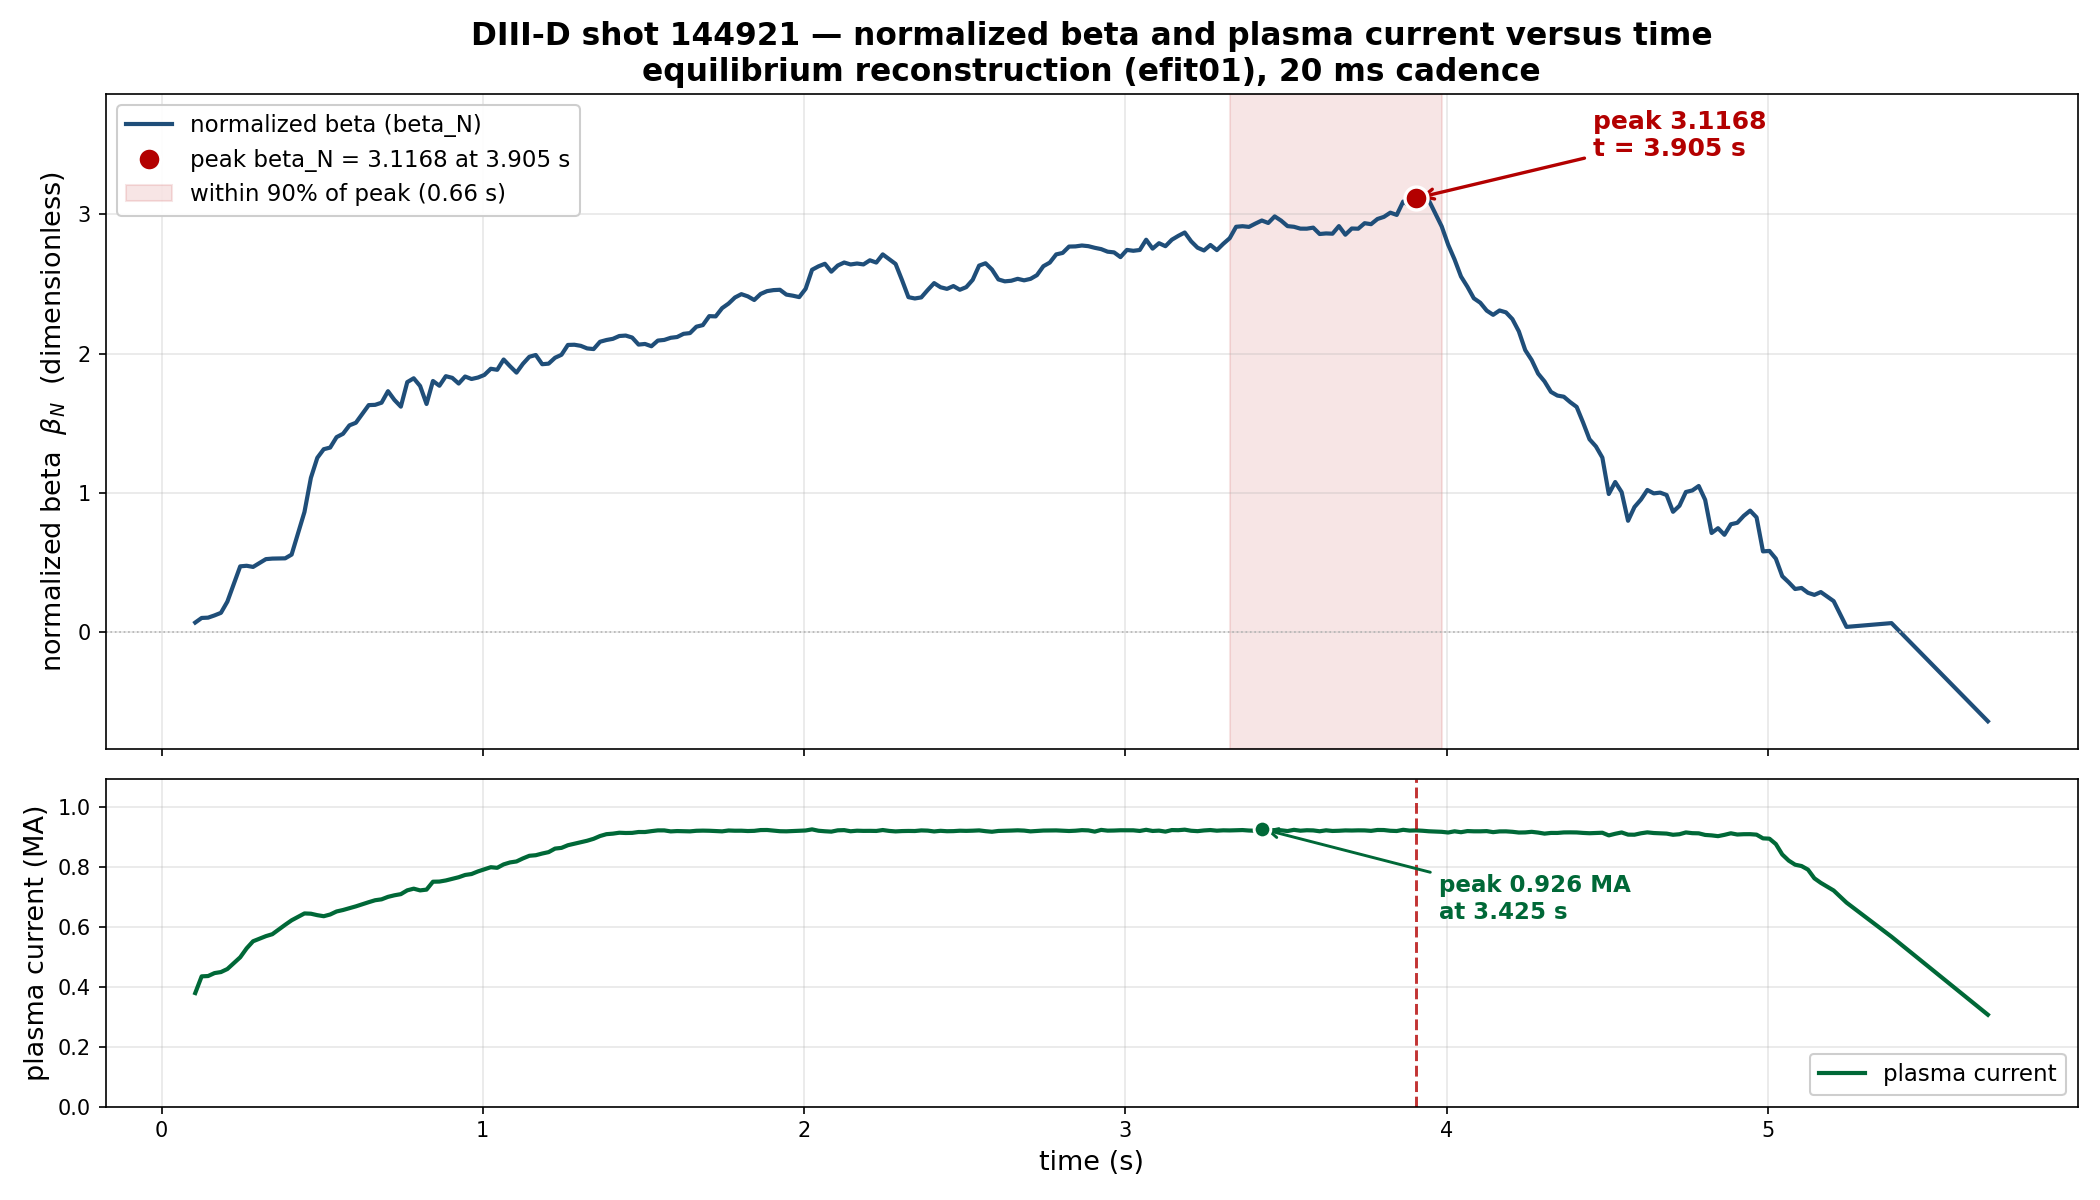

**A caveat on the fuel-gas field.** It is populated on only **35.9%** of the archive (32,506 of 90,644 shots), and shot 144921 is the **highest-numbered shot in the entire archive that carries a value** — the field stops there, with 38,059 later shots having none. So the `D2` reading is solid for this shot, but the field's coverage is a property of the archive's history, not of this discharge. The neighbouring shots show the same patchiness: 144917, 144918 and 144920 carry `D2` while 144915, 144916 and 144919 are blank, so a blank neighbour is a gap in the record rather than evidence of a different gas.

**Data files** (all in the working folder):

- `shot_144921_lookup.json` — the four requested fields as read from the shot record, plus the full 82-field row and the shot-list entry.
- `betan_144921.csv` — the β_N and plasma-current traces, columns `time_ms,betan,ipmhd_A`; every trace number above recomputes from this.
- `betan_144921_stats.json` — peak value and time, the 90%/95%-of-peak windows, neighbour samples, and the negative-sample check.
- `shot_144921_betan_trace.json` — the raw fetch summary: sample counts, time base, units, and top-five samples for both signals.
- `shot_144921_neutrons_units.json` — the yield-versus-rate test across 400 shots, with the correlations and ratio percentiles.
- `shot_144921_gas_gamma.json` — fuel-gas coverage by species across the archive, the gas values of neighbouring shots, and the catalog search for the rate field.
- `shot_144921_meta.json` — column data types, the absence of column comments, the gas-coverage boundary, and the focal shot's full context.
- `shot_144921_catalog.json` — catalog entries for normalized beta, neutron and gas signals, with the description and units for β_N.
- `lookup_144921.py`, `catalog_144921.py`, `fetch_144921_betan.py`, `fetch_144921_traces_csv.py`, `neutrons_units_144921.py`, `gas_gamma_144921.py`, `meta_144921.py`, `plot_144921_betan.py` — the scripts that produced the above.

In [3]:
%%ask
For DIII-D shot 144921, what fuel gas was used, what was the neutron yield,
and what was the peak normalized beta and when did it occur?

In [4]:
%%ask
Did DIII-D shot 96549 have an operational fault, and if so what kind?

## Shot 96549 — yes, a fault is recorded: `IPMIN`, plasma current fell below minimum

**The shot record carries the fault code `IPMIN`.** The archive's own field documentation defines that code as **"plasma current fell below minimum"** — the discharge's plasma current dropped under the minimum threshold the plasma control system enforces, and the shot was terminated on that fault.

**The code is documented, and I read the definition rather than inferring it.** The letters invite a guess, and the guess would be wrong in an interesting way: `IPMIN` is not "minimum current" as a setpoint but a *trip* — the current fell below a floor. The full legend, quoted from the archive's field documentation:

| code | meaning |
|---|---|
| `IPDOT` | IDT exceeded maximum |
| `IPMIN` | plasma current fell below minimum |
| `CHPCUR` | chopper current limit exceeded |
| `CHPIOC` | chopper instantaneous over current (IOC) limit exceeded |
| `ABORT` | abort system fault |
| `FPS` | F power supply fault |
| `XRAY` | xray fault |
| `PCSYS` | plasma control system computer fault |
| `ADP` | ADP ring fault |
| `IPMAX` | maximum plasma current exceeded |
| `NONE` | unknown/undetected fault |

**The fault time is not recorded.** The companion time field is empty for this shot — and empty for **all 21,988** coded shots in the archive, so this is a gap in the field itself, not a property of this shot. The record names the fault but not when it occurred.

**The shot did produce plasma, and a substantial amount of it.** This matters for reading the fault: `IPMIN` is a plasma-control trip, not a machine failure that aborted the shot before it started. The equilibrium reconstruction for 96549 runs 104 samples from 50 to 5,200 ms, with plasma current peaking at **1.194 MA** and stored energy at **0.658 MJ** . Elongation spans 1.47–1.97. So the discharge formed, ramped up, and reached over a mega-ampere before the current fell below the floor.

**The fault is not a disruption label.** No disruption time and no forced-disruption time is recorded for this shot, and across all 21,988 coded shots in the archive **not one** carries either field. The two are independent: a fault code says the control system tripped, not that the plasma disrupted. I also checked the separate disruption index, which covers only shots 194000–199687 — shot 96549 is outside it, so that source cannot speak to this shot either way. I am not claiming the shot did or did not disrupt; the archive does not record it.

**How `IPMIN` compares with the other common code.** The two dominant codes are `IPDOT` (11,750 shots) and `IPMIN` (7,865). Measured across the archive, `IPMIN` shots run **longer** on average (5.34 s vs 3.90 s pulse) at **lower** peak current (1.10 MA vs 1.20 MA) — consistent with a current-floor trip: a discharge that is being run down or has lost current control ends later and lower. This is a population tendency, not a per-shot prediction, and it is corroboration of the documented meaning rather than a substitute for it.

**The fault field is a historical one.** It is populated on 21,988 shots spanning **55103 to 96570** and is blank on every shot above 96570 — the field simply stops being filled in this archive. Within its era it is near-universal: **94.3%** of the 23,319 shots in that range carry a code. So a blank on a modern shot means "not recorded," not "no fault," and this shot's `IPMIN` is a real entry from the era when the field was maintained.

**Context for the shot:** run session `19980605`, one of 33 shots in that session, fuelled with deuterium, 7.45 MJ of neutral-beam energy injected, 116 days and 1,632 shots since the last vessel vent. Its session was dominated by `IPDOT` (29 of 33 shots) with `IPMIN` on 4 — so 96549 was one of a minority in its own session that tripped on the current floor rather than the current-derivative limit.

**One caveat on the record's completeness.** This shot's summary row is sparse — 14 of 82 fields populated, with no pulse length, no peak current, and no shot timestamp recorded, even though the underlying equilibrium data exists and shows a full discharge. The fault code is present and documented; the surrounding bookkeeping for this shot is largely absent. The `IPMIN` reading itself is solid: it is identical in both the trimmed view and the full archive table.

**Data files** (all in the working folder):

- `fault_96549_legend.json` — the full fault-code legend as documented, the `IPMIN` definition, the fault-time field's units and description, and the cross-check of the code between the trimmed and full archive tables.
- `fault_96549_raw.json` — the complete shot record and summary row for 96549, with every field and its type.
- `fault_96549_meaning.json` — the code inventory, the search for a legend, the same-session shot list, and the field's populated range.
- `fault_96549_profile.json` — per-code operational profiles, the fault-time coverage check, and the field-completeness comparison across the session.
- `fault_96549_characterise.json` — current and pulse-length percentiles by code, code prevalence within the field's era, and the adjacent-session code mix.
- `fault_96549_plasma_probe.json` — the equilibrium traces for 96549 and two same-session controls, showing the shot produced plasma.
- `fault_96549_disruption_index.json` — the disruption index's coverage and its explicit refusal for this shot.
- `fault_96549_schema_probe.json` — the schemas and tables searched for a fault-code dictionary.
- `fault_96549_doc_search.json` — the documentation tables and the search that located the legend.
- `fault_96549_controls.json` — no-fault shots near 96549 and the pulse-length distributions by code.
- `fault_96549.py`, `fault_96549_meaning.py`, `fault_96549_profile.py`, `fault_96549_characterise.py`, `fault_96549_plasma_probe.py`, `fault_96549_disruption_index.py`, `fault_96549_legend_search.py`, `fault_96549_schema_probe.py`, `fault_96549_doc_search.py`, `fault_96549_legend.py`, `fault_96549_controls.py` — the scripts that produced the above.

In [ ]:
%%ask
What was the effective ion charge (Zeff) for DIII-D shot 165340?

In [5]:
%%ask
What run date is DIII-D shot 165340 from, and who entered the record?

## Shot 165340 — run date and record author

**Run date: 2016-01-28 (Thursday).** The shot belongs to run session **`20160128`** , which decodes directly to 28 January 2016. The session's title was **"Helicon Coupling in High Performance Plasmas"** , experiment number **2016-14-04** , configured for **double-null** operation.

**The run label and the shot's own timestamp agree.** The shot fired at **10:46:13** on 2016-01-28, and the run label decodes to the same calendar day. I checked this across a 2,000-shot sample of the archive: **2,000 of 2,000** had a run label matching the shot's recorded date, so the label is a reliable date field rather than a loose grouping.

**Who entered the record: not recorded.** The author field is **empty** for this shot. I am reporting that as an absence in the data, not as a failure to look — here is what I checked:

| where an author could live | result for shot 165340 |
|---|---|
| shot record's author field | empty |
| shot record's chief-operator field | empty |
| run-session record's author field | empty |
| all four logbook entries for this shot | author empty on every one |
| pre-shot setup record | no row exists for this shot |

**The field is empty archive-wide, not just for this shot.** The author field holds a value on **0 of 90,644** shots in the trimmed view and **0 of 168,092** in the full database. The same is true of the chief-operator field, and of the author field in every other table that has one — logbook entries (0 of 497,776), run sessions (0 of 8,362), pre-shot records (0 of 11,144), and the rest. So this is a field the archive carries but does not populate, and no amount of further querying will produce a name for this shot.

**The free-text note is not an author, and I did not treat it as one.** The shot's short description reads `autoload system Thu Jan 28 10:46:36 2016`. That is a process name and a timestamp, not a person — and it is the same string on **65,811 of 90,644** shots, which is the signature of an automated loader rather than a human entry. Its timestamp also runs **+29.1 s** after the record-entry time, consistently across all ten shots of the session (+28.8 to +29.3 s), so it is a later automated stamp, not the moment of entry. Quoting it as "who entered the record" would report a machine as a person.

**What the record does tell us about how it was created.** The shot's source is `rdata` — one of three source values in the archive (`rdata` 64,884, `autocorrect` 25,485, `user` 275). This shot came in through the automated data path, not a manual user entry. Even the 275 shots explicitly marked as user-sourced carry no author name, so the manual path does not populate the field either.

**The logbook does name people, but only inside free text.** The four entries for this shot are a PCS parameter-change log, a physics-operator note ("Replace HX2 with HX11 on F7A / try again / Good shot"), a session-leader note ("Try 481 MHz / Result: good"), and a chief-operator note ("Plasma,ok"). The PCS entry's text contains the token `degrassi` — but that is a **software account name embedded in a parameter-change message** , appearing as `degrassi: change parameter data: ...`, and the same pattern appears for other accounts (`chrobak`, `coon`, `hyatt`, `timcon`) elsewhere in the session. It identifies whose saved PCS configuration was applied, not who wrote the record. I am not presenting it as the record's author.

**One caveat on the run date.** The run label is a session identifier, and a session can in principle span midnight. For this shot the two agree exactly, so the date is unambiguous. The record-entry timestamp is **2016-01-28 10:46:06.890** , about 6 seconds before the shot fired — the bookkeeping lag noted earlier in this session.

**Data files** (all in the working folder):

- `run_165340.json` — the shot's run label, entry timestamp, author fields, and the ten shots of session `20160128` with their entry times and descriptions.
- `run_165340_verify.json` — field documentation, the table inventory, the author-field coverage counts, and the shot-time cross-check.
- `run_165340_attribution.json` — the source-value inventory, the run-label-versus-date test across 2,000 shots, and the description-timestamp offsets for the session.
- `run_165340_deep.json` — the full database's table list, every person-like column across all tables, and the shot row from the full database.
- `run_165340_author_probe.json` — the run-session, logbook-entry, pre-shot and saved-configuration records for this shot, with their author fields.
- `run_165340_logbook.json` — all four logbook entries for the shot in full, plus the session's complete entry list.
- `run_165340_personnel.json` — author-field coverage for every table that has one, and the run session's full metadata.
- `run_165340.py`, `run_165340_verify.py`, `run_165340_attribution.py`, `run_165340_deep.py`, `run_165340_author_probe.py`, `run_165340_logbook.py`, `run_165340_personnel.py` — the scripts that produced the above.

## 3. PTDATA — basic access test

**Purpose:** verify PTDATA (a separate data source from the MDSplus trees used above) is reachable end to end through ARGUS.

**Ask:** fetch the plasma current from PTDATA (not efit01) for a known shot
and report basic stats.

**Expected:** a successful fetch, ~30,720 samples, peak current near 1.15 MA —
this is a raw digitizer trace, a different diagnostic pipeline than efit01's
`\ipmhd`, so don't expect an identical peak to the efit01 numbers seen earlier
in this notebook.


In [ ]:
%%ask
Fetch the plasma current from PTDATA (not the MHD equilibrium reconstruction)
for DIII-D shot 165920, and report the number of samples and the min/max with
units.

In [ ]:
%%ask
For DIII-D shot 165920, fetch the plasma current from BOTH PTDATA and the
efit01 MHD equilibrium reconstruction, and compare their peak values and
units. Are they consistent with each other?

## 4. Signal meanings, paths, and IMAS names

Different ways to ask about the *same* signal -- plain-English meaning, its exact MDSplus path, and its IMAS (device-neutral) name -- to see how ARGUS handles each.

In [ ]:
%%ask
what is the meaning of \FS02UPDA and \EFIT01::BT0VAC in plain English?

In [ ]:
%%ask
What is the full path of \EFIT01::CPASMA?

In [ ]:
%%ask
Do you know the IMAS name for \EFIT01::CPASMA?

In [ ]:
%%ask
For DIII-D shot 165920, fetch equilibrium.time_slice[i].global_quantities.ip
and plot it versus time